# Part 4: Final Comparison and Conclusion
**Student Dropout and Academic Success: Supervised Classification (3 classes)**

**Author:** Member B  |  **Course:** IT5022 Fundamentals of Machine Learning

This notebook combines the results of the two algorithms:
- **Logistic Regression** (Member A, `02_logistic_regression.ipynb`)
- **Random Forest** (Member B, `03_random_forest.ipynb`)

Both were trained and tested on exactly the same data, and each was tried with three imbalance strategies
(baseline, class-weighted, SMOTE). **Run notebooks 01, 02 and 03 before this one.**


## 1. Load both result files

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Each file was saved by the model notebooks and has the same columns
lr = pd.read_csv("../results/logreg_results.csv")
rf = pd.read_csv("../results/rf_results.csv")

# Stack them into one table
all_results = pd.concat([lr, rf], ignore_index=True).set_index("Model").round(4)
all_results


,Accuracy,Macro F1,Recall (Dropout),Recall (Enrolled),Recall (Graduate)
Model,,,,,
LR - Baseline,0.7718,0.6938,0.7641,0.3711,0.9208
LR - Class-weighted,0.7288,0.6904,0.7007,0.6164,0.7873
LR - SMOTE,0.7288,0.6893,0.7148,0.5975,0.7851
RF - Baseline,0.7616,0.6552,0.7606,0.2453,0.9480
RF - Class-weighted,0.7627,0.7052,0.7183,0.5031,0.8846
RF - SMOTE,0.7740,0.7062,0.7500,0.4340,0.9118


## 2. Compare all six models

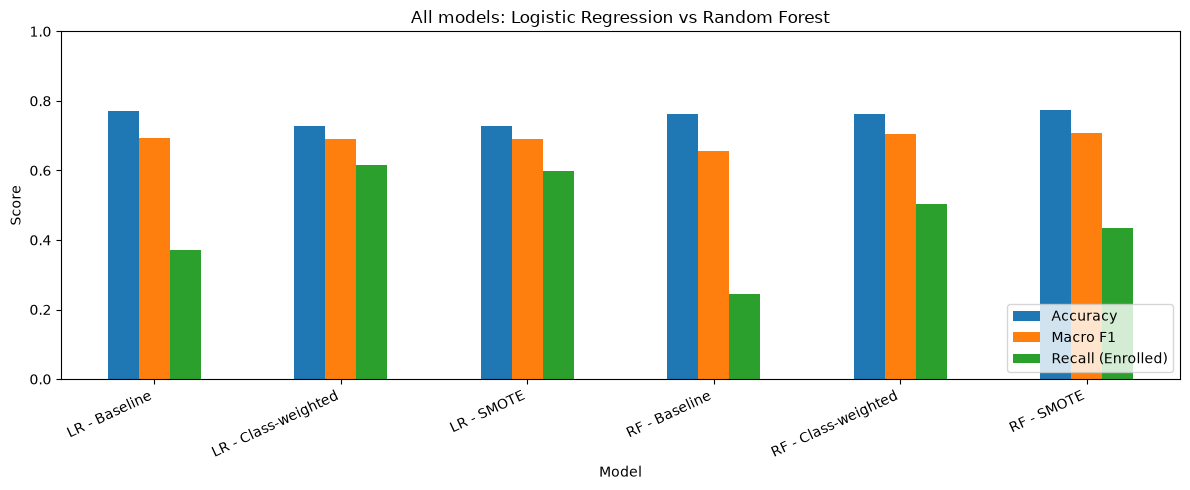

In [2]:
# Overall chart: accuracy, macro F1 and recall on the small "Enrolled" class
all_results[["Accuracy", "Macro F1", "Recall (Enrolled)"]].plot(kind="bar", figsize=(12, 5))
plt.title("All models: Logistic Regression vs Random Forest")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 3. Which model is best?

In [3]:
# Best model on each measure
print("Highest accuracy          :", all_results["Accuracy"].idxmax(), "->", all_results["Accuracy"].max())
print("Highest macro F1          :", all_results["Macro F1"].idxmax(), "->", all_results["Macro F1"].max())
print("Highest Enrolled recall   :", all_results["Recall (Enrolled)"].idxmax(), "->", all_results["Recall (Enrolled)"].max())


Highest accuracy          : RF - SMOTE -> 0.774
Highest macro F1          : RF - SMOTE -> 0.7062
Highest Enrolled recall   : LR - Class-weighted -> 0.6164


## 4. Final conclusion

**Summary of results (test set, 885 students)**

| Model | Accuracy | Macro F1 | Recall (Enrolled) |
|---|---|---|---|
| LR - Baseline | 0.772 | 0.694 | 0.371 |
| LR - Class-weighted | 0.729 | 0.690 | **0.616** |
| LR - SMOTE | 0.729 | 0.690 | 0.598 |
| RF - Baseline | 0.762 | 0.655 | 0.245 |
| RF - Class-weighted | 0.764 | 0.666 | 0.270 |
| RF - SMOTE | **0.774** | **0.706** | 0.434 |

**Main findings**
1. **The data is imbalanced** (Graduate 50%, Dropout 32%, Enrolled 18%). Both algorithms, left on default settings, miss most "Enrolled" students (recall 37% for Logistic Regression and 25% for Random Forest), even though their accuracy looks fine at about 76-77%. Accuracy alone would have hidden this.
2. **Imbalance handling helps, but the best method depends on the algorithm.** For Logistic Regression, class-weighting and SMOTE raise Enrolled recall to about 60%. For Random Forest, class-weighting barely helps, while SMOTE raises it from 25% to 43%.
3. **Random Forest with SMOTE is the best overall model.** It has the highest accuracy (77.4%) and the highest macro F1 (0.706).
4. **Logistic Regression with class-weighting is best at finding Enrolled students** (61.6% recall), but it pays for this with lower accuracy (72.9%).
5. **There is a trade-off, and the right choice depends on the goal.** If the university wants the best balanced model, use Random Forest with SMOTE. If it wants to identify as many undecided students as possible for early support, use class-weighted Logistic Regression.
6. **Academic results matter most.** Subjects approved and grades in the first two semesters are the strongest predictors of the outcome, followed by tuition payment status and age at enrollment.

**Limitations**
- "Enrolled" is hard to predict because it is an unfinished outcome: these students have not yet graduated or dropped out.
- The data comes from one institution, so the results may not apply to other universities.
- We used a single 80/20 split and mostly default model settings. Tuning the models and using cross-validation could improve the results.


## References
- Realinho, V., Vieira Martins, M., Machado, J. and Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89 (CC BY 4.0)
- Martins, M.V., Tolledo, D., Machado, J., Baptista, L.M.T. and Realinho, V. (2021). *Early prediction of student's performance in higher education: a case study.* WorldCIST 2021.
- Chawla, N.V., Bowyer, K.W., Hall, L.O. and Kegelmeyer, W.P. (2002). *SMOTE: Synthetic Minority Over-sampling Technique.* Journal of Artificial Intelligence Research, 16, 321-357.
